# Extra Trees (Extremely Randomized Trees)

A Random Forest (`19_random_forest`) with two changes that add even more randomness:

| | Random Forest | Extra Trees |
|---|---|---|
| Training rows per tree | bootstrap sample | the **whole** set (by default) |
| Candidate features per split | random subset | random subset |
| Split threshold | **best** cut, found by scanning | **random** cut, uniform in the feature's range |

At each node, a random threshold is drawn for each candidate feature and the best-scoring of those random splits wins. Because nothing is sorted or scanned for the optimum, each tree is much cheaper to build, and the extra randomness decorrelates the trees further — lowering ensemble variance at the cost of slightly higher bias per tree. Averaging many trees makes up for the weaker individual splits.

## Usage

```python
# (the class is defined in the Implementation section below)

model = ExtraTreesClassifier(n_estimators=100).fit(X_train, y_train)
preds = model.predict(X_test)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class _ExtraTree:
    """At each node: pick random features, pick a RANDOM threshold for each (uniform between that
    feature's min and max in the node), and keep whichever random split has the best Gini score.
    No searching for the optimal threshold -- that is the whole idea."""

    def __init__(self, max_depth, min_samples_split, max_features, n_classes, rng):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_features = max_features
        self.n_classes = n_classes
        self.rng = rng

    def fit(self, X, y):
        self.root = self._grow(X, np.eye(self.n_classes)[y], 0)
        return self

    def predict(self, X):
        return np.array([self._traverse(x, self.root) for x in X])

    def _grow(self, X, Y, depth):
        counts = Y.sum(axis=0)
        n = len(Y)
        if depth >= self.max_depth or n < self.min_samples_split or counts.max() == n:
            return counts.argmax()

        best_score, best_feature, best_threshold = -np.inf, None, None
        for f in self.rng.choice(X.shape[1], self.max_features, replace=False):
            lo, hi = X[:, f].min(), X[:, f].max()
            if lo == hi:
                continue
            t = self.rng.uniform(lo, hi)  # random cut point
            mask = X[:, f] <= t
            left, right = Y[mask].sum(axis=0), Y[~mask].sum(axis=0)
            # sum(c^2/n) over both sides; larger == lower weighted Gini impurity
            score = (left**2).sum() / mask.sum() + (right**2).sum() / (~mask).sum()
            if score > best_score:
                best_score, best_feature, best_threshold = score, f, t

        if best_feature is None:
            return counts.argmax()
        mask = X[:, best_feature] <= best_threshold
        return (best_feature, best_threshold,
                self._grow(X[mask], Y[mask], depth + 1), self._grow(X[~mask], Y[~mask], depth + 1))

    def _traverse(self, x, node):
        while isinstance(node, tuple):
            feature, threshold, left, right = node
            node = left if x[feature] <= threshold else right
        return node


class ExtraTreesClassifier:
    """Extremely Randomized Trees. Like Random Forest, but split thresholds are drawn at random
    instead of optimized, and by default every tree sees the WHOLE training set (no bootstrap).

    More randomness -> the trees are more decorrelated and each one is cheaper to build (no sorting
    or scanning for the best cut), so the ensemble has lower variance, at the price of slightly
    higher bias per tree."""

    def __init__(self, n_estimators=50, max_depth=12, min_samples_split=2, max_features="sqrt",
                 bootstrap=False, random_state=0):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.max_features = max_features
        self.bootstrap = bootstrap
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_, y_enc = np.unique(y, return_inverse=True)
        n, d = X.shape
        k = len(self.classes_)
        max_features = max(1, int(np.sqrt(d))) if self.max_features == "sqrt" else self.max_features

        rng = np.random.default_rng(self.random_state)
        self.trees = []
        for _ in range(self.n_estimators):
            idx = rng.integers(0, n, n) if self.bootstrap else np.arange(n)
            tree = _ExtraTree(self.max_depth, self.min_samples_split, max_features, k, rng)
            self.trees.append(tree.fit(X[idx], y_enc[idx]))
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        votes = np.array([t.predict(X) for t in self.trees])
        k = len(self.classes_)
        return self.classes_[[np.bincount(col, minlength=k).argmax() for col in votes.T]]

## See it work

### 1. Random thresholds give smoother boundaries

A random forest searches for the **best** threshold on each candidate feature. Extra Trees (extremely randomised trees) draws the threshold **at random** and only picks which feature is best among those random splits. Individual trees are worse, but they are more diverse, and the average is smoother.

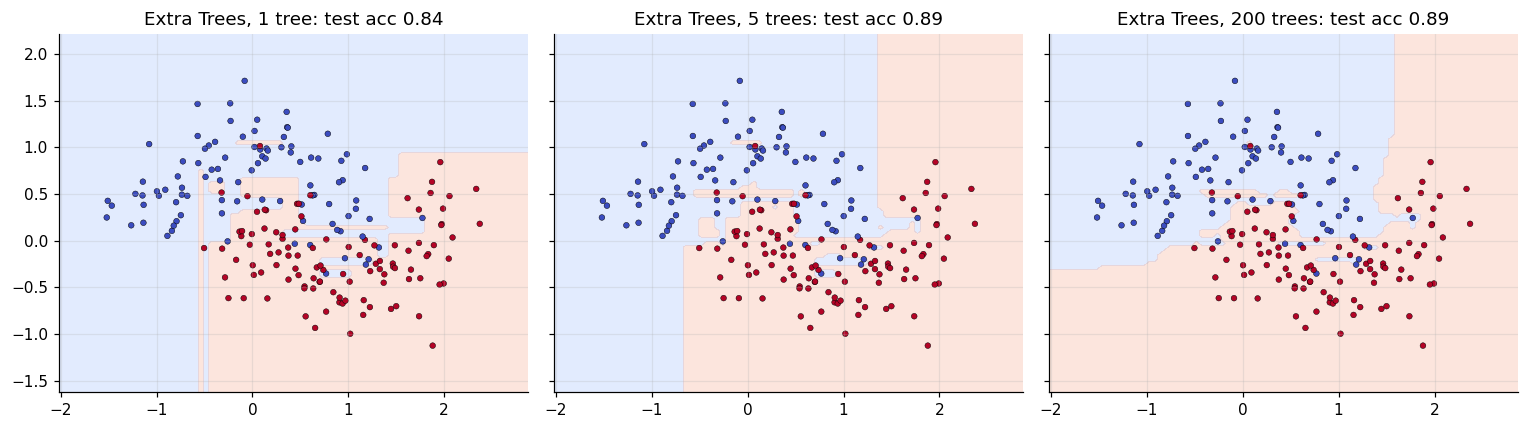

In [3]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
def plot_boundary(ax, model, X, y, cmap="coolwarm", n=150, pad=0.5):
    """Colour the plane by the model's predicted class, then draw the data on top."""
    gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, n), np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, n))
    pred = np.asarray(model.predict(np.c_[gx.ravel(), gy.ravel()])).reshape(gx.shape)
    K = len(np.unique(y))
    ax.contourf(gx, gy, pred, alpha=0.25, cmap=cmap, levels=np.arange(-0.5, K + 0.5) if K > 2 else [-0.5, 0.5, 1.5])
    ax.scatter(*X.T, c=y, cmap=cmap, s=14, edgecolor="k", linewidth=0.3)

Xm, ym = make_moons(n_samples=400, noise=0.3, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(Xm, ym, test_size=0.5, random_state=0)
acc = lambda m, X, y: (m.predict(X) == y).mean()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (name, m) in zip(axes, [("Extra Trees, 1 tree", ExtraTreesClassifier(n_estimators=1, max_depth=12, max_features=2)), ("Extra Trees, 5 trees", ExtraTreesClassifier(n_estimators=5, max_depth=12, max_features=2)), ("Extra Trees, 200 trees", ExtraTreesClassifier(n_estimators=200, max_depth=12, max_features=2))]):
    m.fit(Xtr, ytr); plot_boundary(ax, m, Xtr, ytr, n=90); ax.set_title(f"{name}: test acc {acc(m, Xte, yte):.2f}")
plt.tight_layout(); plt.show()

### 2. An ensemble of random trees vs a single one

One extremely-randomised tree is a weak, noisy classifier (its thresholds are random). Averaging many of them gives a strong one, on a 20-feature problem with 8 informative features.

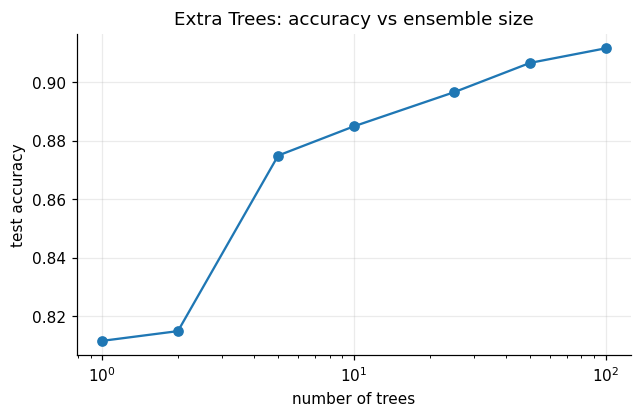

In [4]:
from sklearn.datasets import make_classification

Xb, yb = make_classification(n_samples=1500, n_features=20, n_informative=8, random_state=0)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.4, random_state=0)
ns = [1, 2, 5, 10, 25, 50, 100]
te = [(ExtraTreesClassifier(n_estimators=n, max_depth=10).fit(Xb_tr, yb_tr).predict(Xb_te) == yb_te).mean() for n in ns]
plt.figure(figsize=(6.5, 3.8)); plt.semilogx(ns, te, "o-"); plt.xlabel("number of trees"); plt.ylabel("test accuracy"); plt.title("Extra Trees: accuracy vs ensemble size"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [5]:
from sklearn.datasets import load_wine
from sklearn.ensemble import ExtraTreesClassifier as SklearnExtraTrees
from sklearn.model_selection import train_test_split

data = load_wine()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.3, random_state=42
)

ours = ExtraTreesClassifier(n_estimators=100).fit(X_train, y_train)
theirs = SklearnExtraTrees(n_estimators=100, random_state=0).fit(X_train, y_train)

acc_ours = (ours.predict(X_test) == y_test).mean()
acc_theirs = (theirs.predict(X_test) == y_test).mean()
print("wine test accuracy: ours=%.4f sklearn=%.4f" % (acc_ours, acc_theirs))
assert abs(acc_ours - acc_theirs) < 0.06  # random forests of any kind: close, not identical

wine test accuracy: ours=1.0000 sklearn=1.0000


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [6]:
import numpy as np


def test_string_labels_and_separable_data():
    rng = np.random.default_rng(0)
    X = np.vstack([rng.normal(-3, 0.6, (60, 3)), rng.normal(3, 0.6, (60, 3))])
    y = np.array(["cat"] * 60 + ["dog"] * 60)
    model = ExtraTreesClassifier(n_estimators=20).fit(X, y)
    preds = model.predict(X)
    assert set(preds) <= {"cat", "dog"}
    assert (preds == y).mean() > 0.98


def test_thresholds_are_random_not_optimized():
    # one clean split exists at ~5; different seeds must still pick different cut points
    X = np.array([[1.0], [2.0], [3.0], [7.0], [8.0], [9.0]])
    y = np.array([0, 0, 0, 1, 1, 1])
    cuts = set()
    for seed in range(8):
        tree = _ExtraTree(1, 2, 1, 2, np.random.default_rng(seed)).fit(X, y)
        cuts.add(round(tree.root[1], 3))
    assert len(cuts) > 4
    assert all(1.0 <= c <= 9.0 for c in cuts)


def test_iris_accuracy_and_determinism():
    from sklearn.datasets import load_iris
    from sklearn.model_selection import train_test_split

    data = load_iris()
    X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.3, random_state=0)
    a = ExtraTreesClassifier(n_estimators=40, random_state=3).fit(X_train, y_train)
    b = ExtraTreesClassifier(n_estimators=40, random_state=3).fit(X_train, y_train)
    assert (a.predict(X_test) == y_test).mean() > 0.9
    assert (a.predict(X_test) == b.predict(X_test)).all()

In [7]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_string_labels_and_separable_data
PASS test_thresholds_are_random_not_optimized
PASS test_iris_accuracy_and_determinism

all 3 tests passed


## Takeaways

- **Use it** when you want a Random-Forest-like model that is cheaper to train (no search for the best cut point) and even smoother; with noisy features, the extra randomness acts as regularisation.
- **Differences from RF:** thresholds are drawn uniformly at random between the feature's min and max, and by default no bootstrap (each tree sees all the data); higher bias per tree, lower variance in the ensemble.
- **Interview line:** *"Extra Trees = random forest with random split thresholds: more bias per tree, less variance across trees, and cheaper to train."*